In [1]:
import numpy as np
import os 
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import savgol_filter
from sklearn.preprocessing import MinMaxScaler
import warnings
from scipy import stats
import seaborn as sns
import scipy.ndimage
import scipy.stats as stats
from scipy.ndimage import gaussian_filter1d
from scipy.stats import ranksums
from numba import jit
import matplotlib as mpl
import random
import pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from typing import List, Tuple, Dict, Literal
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

import gzip
import sys

# Add the folder containing your modules to the path
folder_path = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code'  # Replace with actual path
sys.path.insert(0, folder_path)

from avc_analysis import *
analysis = avc_analysis()
plotter = avc_plotting()

from data_loading import *

loader = DataLoader()  

#figures_dir = 

from matplotlib import rcParams

# Set publication style
rcParams['font.family'] = 'Arial'

In [2]:
mouse_ID = 'IS-2-1L' 
date = '2025-03-12'

In [3]:
save_path = f'/Volumes/Akhil Data/Akhil/ProcessedData/{mouse_ID}/{date}/glm_data_dict.pkl.gz'
with gzip.open(save_path, 'rb') as f:
    glm_data_dict = pickle.load(f)

In [4]:
trial_num = 0
glm_data_dict[trial_num].keys()

dict_keys(['trial_id', 'context', 'choice', 'outcome', 'trial_type', 'Visual_Stim', 'Audio_Stim', 'neural', 'movement', 'events'])

In [5]:
glm_data_dict[trial_num]['context'], glm_data_dict[trial_num]['Visual_Stim'], glm_data_dict[trial_num]['Audio_Stim'], glm_data_dict[trial_num]['choice'], glm_data_dict[trial_num]['outcome']

(0, 90.0, 1.0, 1, 1)

In [6]:
glm_data_dict[trial_num]['neural']

{'dff': array([[ 0.01276584,  0.14866864,  0.28688948, ...,  0.12812078,
          0.19741309,  0.05445286],
        [-0.01844638,  0.06864817,  0.15641268, ...,  0.16378378,
          0.18836902,  0.10577189],
        [ 0.26347693,  0.17294365,  0.0779138 , ...,  0.2333744 ,
          0.17117119, -0.04511782],
        ...,
        [ 0.16923739,  0.27500627,  0.13437783, ...,  0.0990717 ,
         -0.02832192,  0.0224767 ],
        [ 0.3187022 ,  0.15098438,  0.17417373, ...,  0.17376462,
          0.21371483, -0.00190885],
        [ 0.00564063,  0.29920879,  0.21248319, ...,  0.10802968,
          0.19322283,  0.10708473]]),
 'deconv': array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 'z_dff': array([[-1.13672474, -0.11836621,  0.35418957, ..., -0.11053185,
          0.28594009, -0.4629308

In [8]:
# Cell 7: Setup and basic info (list-based glm_data_dict)

# Trials are stored as a list: glm_data_dict[trial_index]
n_trials = len(glm_data_dict)
trial_ids = list(range(n_trials))  # use integer indices as trial IDs

example_trial = glm_data_dict[0]
n_neurons = example_trial['neural']['deconv'].shape[1]

print(f"Number of trials: {n_trials}")
print(f"Number of neurons: {n_neurons}")

# Check trial lengths
all_lengths = [glm_data_dict[tid]['neural']['deconv'].shape[0] for tid in trial_ids]
print(f"Trial length range: {min(all_lengths)} to {max(all_lengths)} frames")
max_frames = min(250, max(all_lengths))  # Adjust as needed
print(f"Using max_frames per trial: {max_frames}")

contexts = [0, 1, 2]
choices = [0, 1]  # 0 = Left, 1 = Right
fs = 15.6  # Sampling rate in Hz
time_axis = np.arange(max_frames) / fs

Number of trials: 287
Number of neurons: 1783
Trial length range: 142 to 308 frames
Using max_frames per trial: 250


In [9]:
# Cell 8: Helper functions (list-based glm_data_dict)

def get_condition_trial_ids(ctx, choice):
    """Return list of integer trial indices with given context and choice."""
    cond_trials = []
    for tid in trial_ids:
        t = glm_data_dict[tid]
        if t.get('context', None) == ctx and t.get('choice', None) == choice:
            cond_trials.append(tid)
    return cond_trials


def trial_average_neuron(neuron_idx, ctx, choice, max_frames=max_frames):
    """
    For a given neuron and (context, choice), compute trial-averaged deconv trace.
    """
    cond_trials = get_condition_trial_ids(ctx, choice)
    if len(cond_trials) == 0:
        return None, 0

    # Array: (n_trials, max_frames)
    traces = np.full((len(cond_trials), max_frames), np.nan, dtype=float)

    for i, tid in enumerate(cond_trials):
        deconv = glm_data_dict[tid]['neural']['deconv']  # (T, N)
        T = deconv.shape[0]
        T_use = min(T, max_frames)
        traces[i, :T_use] = deconv[:T_use, neuron_idx]

    mean_trace = np.nanmean(traces, axis=0)
    return mean_trace, len(cond_trials)


def trial_average_population(ctx, choice, max_frames=max_frames):
    """
    Compute population-averaged deconv activity for given (context, choice).
    Average over both trials and neurons.
    """
    cond_trials = get_condition_trial_ids(ctx, choice)
    if len(cond_trials) == 0:
        return None, 0

    n_trials_cond = len(cond_trials)
    pop_traces = np.full((n_trials_cond, max_frames, n_neurons), np.nan, dtype=float)

    for i, tid in enumerate(cond_trials):
        deconv = glm_data_dict[tid]['neural']['deconv']  # (T, N)
        T = deconv.shape[0]
        T_use = min(T, max_frames)
        pop_traces[i, :T_use, :] = deconv[:T_use, :]

    # Average over neurons, then over trials
    mean_across_neurons = np.nanmean(pop_traces, axis=2)       # (n_trials_cond, max_frames)
    pop_mean_trace = np.nanmean(mean_across_neurons, axis=0)   # (max_frames,)

    return pop_mean_trace, n_trials_cond

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68119/3092630573.py:30: RuntimeWarning: Mean of empty slice
  mean_trace = np.nanmean(traces, axis=0)


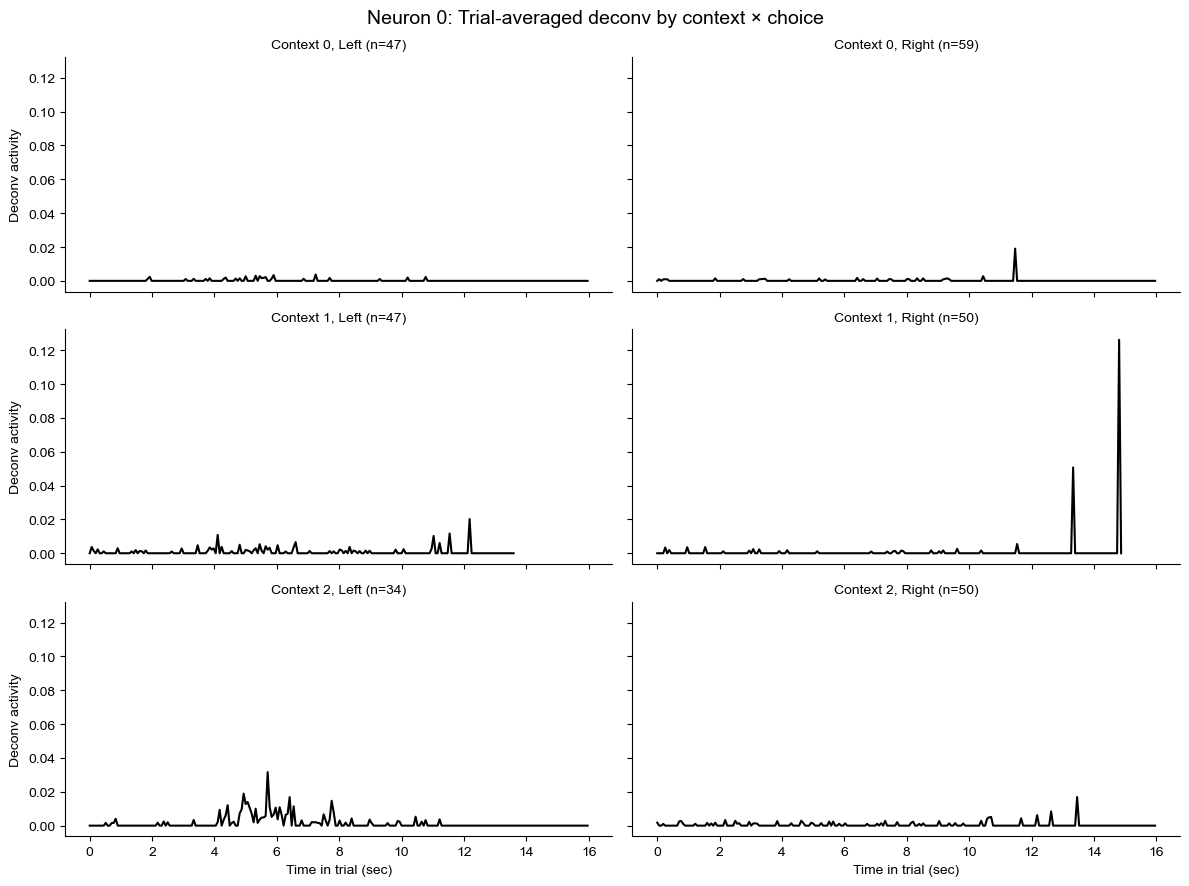

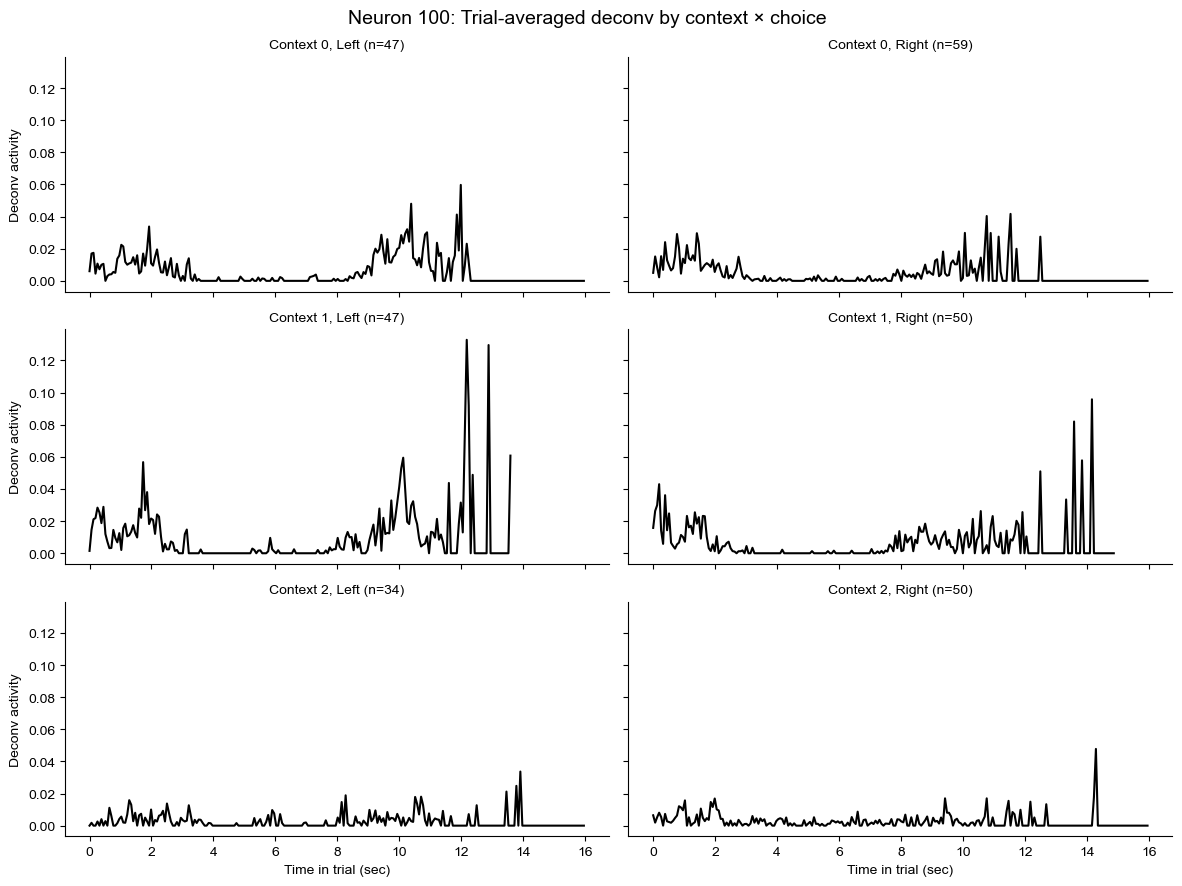

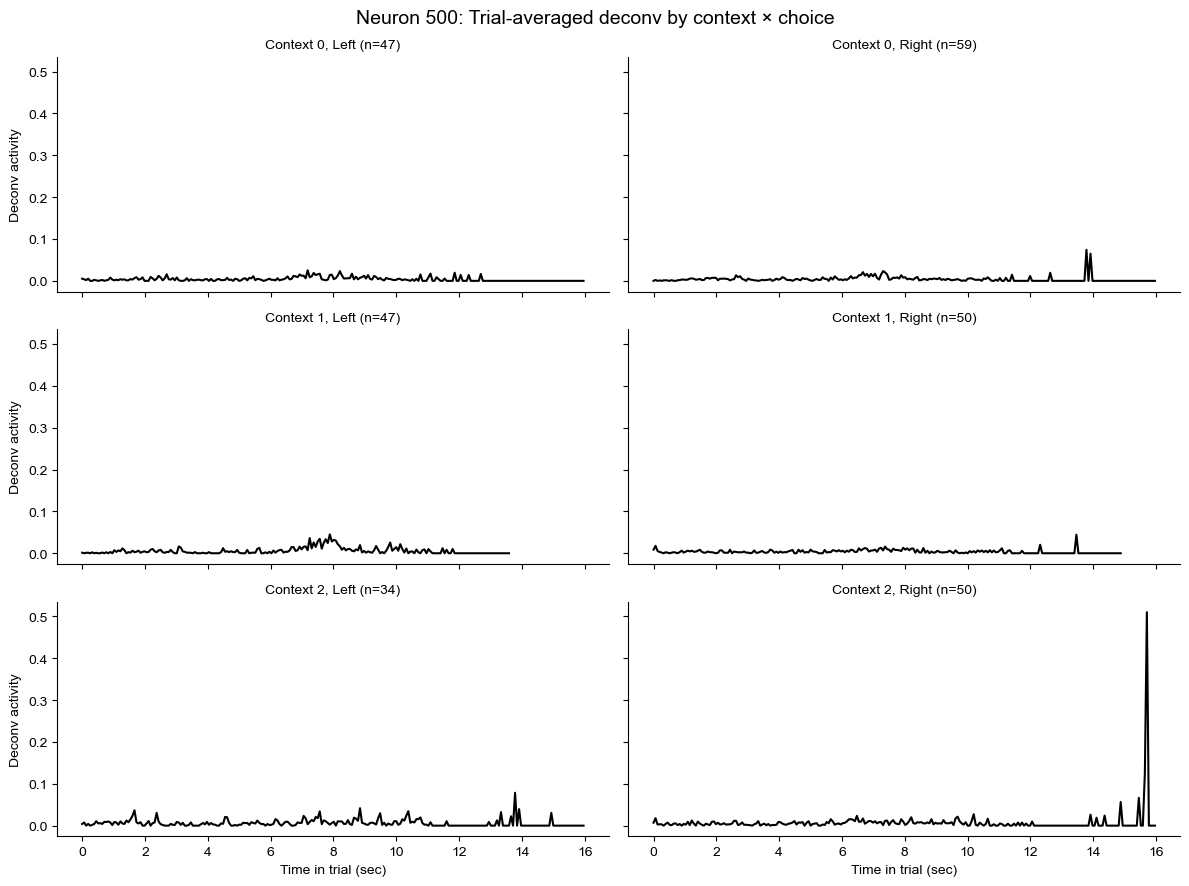

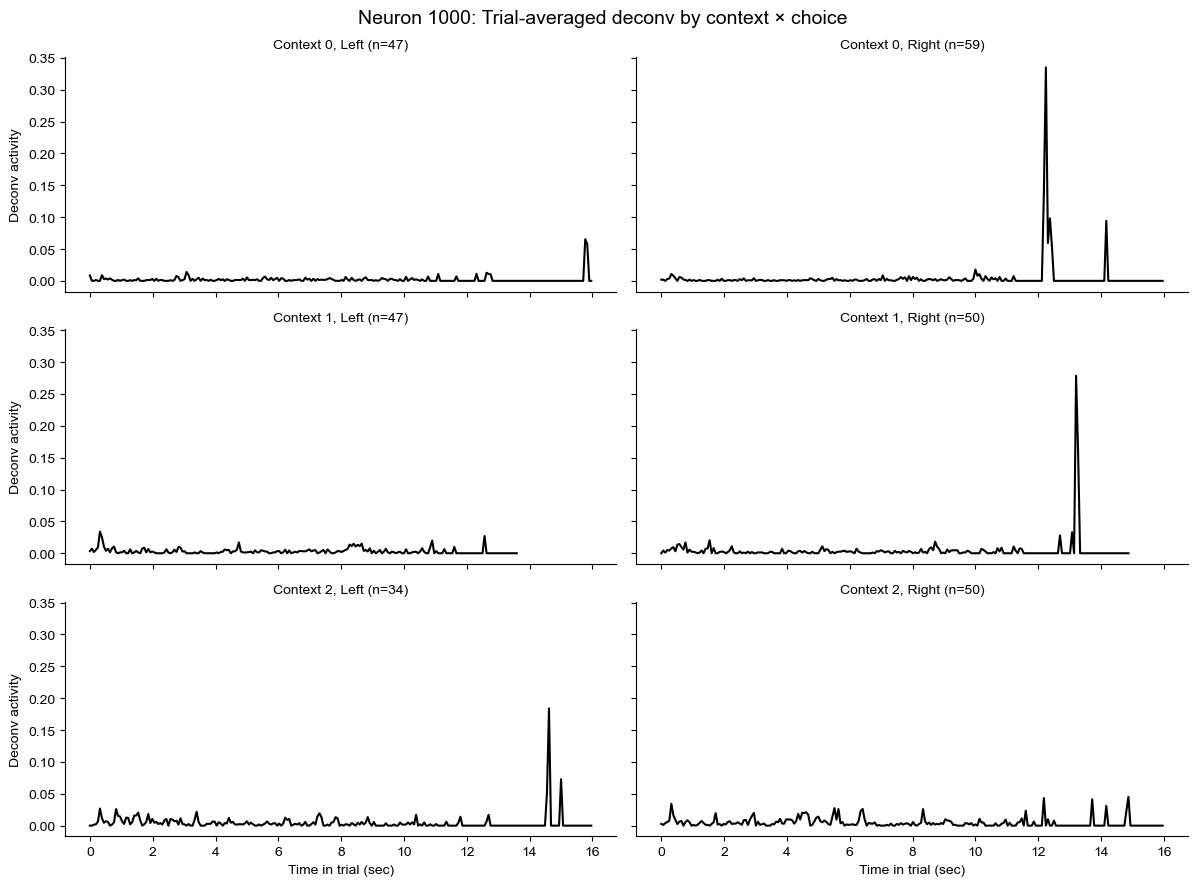

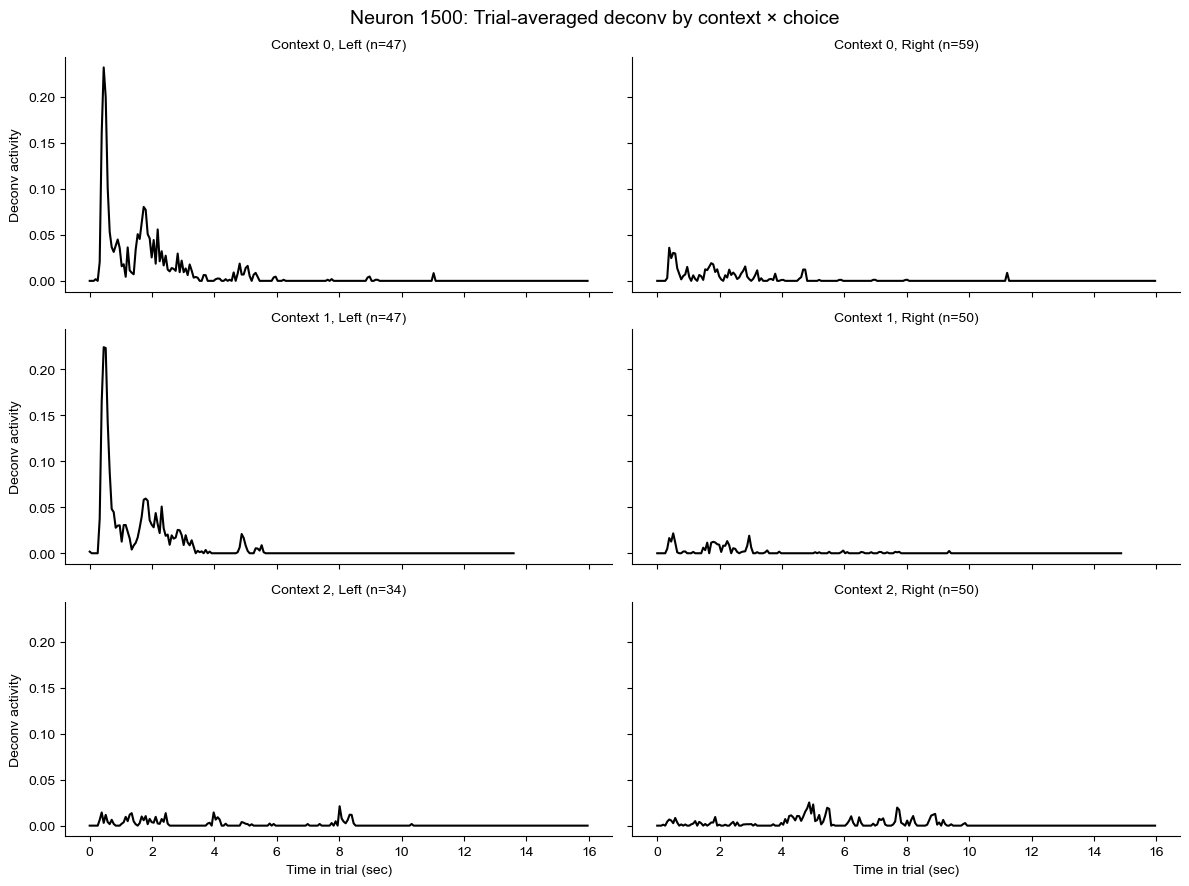

In [12]:
# Cell 9: Plot trial-averaged deconv for example neurons
example_neurons = [0, 100, 500, 1000, 1500]

for i_neuron in example_neurons:
    fig, axes = plt.subplots(len(contexts), len(choices),
                             figsize=(12, 3*len(contexts)), 
                             sharex=True, sharey=True)
    fig.suptitle(f"Neuron {i_neuron}: Trial-averaged deconv by context × choice",
                 fontsize=14, y=0.98)

    for i_ctx, ctx in enumerate(contexts):
        for j_ch, ch in enumerate(choices):
            ax = axes[i_ctx, j_ch]

            mean_trace, n_trials = trial_average_neuron(i_neuron, ctx, ch)
            if mean_trace is None or n_trials == 0:
                ax.text(0.5, 0.5, "No trials", ha="center", va="center",
                        transform=ax.transAxes)
                ax.set_axis_off()
                continue

            label = f"Context {ctx}, {'Left' if ch == 0 else 'Right'} (n={n_trials})"
            ax.plot(time_axis, mean_trace, 'k', lw=1.5)
            ax.set_title(label, fontsize=10)
            #ax.grid(alpha=0.3)

            if j_ch == 0:
                ax.set_ylabel("Deconv activity")
            if i_ctx == len(contexts)-1:
                ax.set_xlabel("Time in trial (sec)")

    plt.tight_layout()
    plt.show()

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68119/3092630573.py:53: RuntimeWarning: Mean of empty slice
  mean_across_neurons = np.nanmean(pop_traces, axis=2)       # (n_trials_cond, max_frames)
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_68119/3092630573.py:54: RuntimeWarning: Mean of empty slice
  pop_mean_trace = np.nanmean(mean_across_neurons, axis=0)   # (max_frames,)


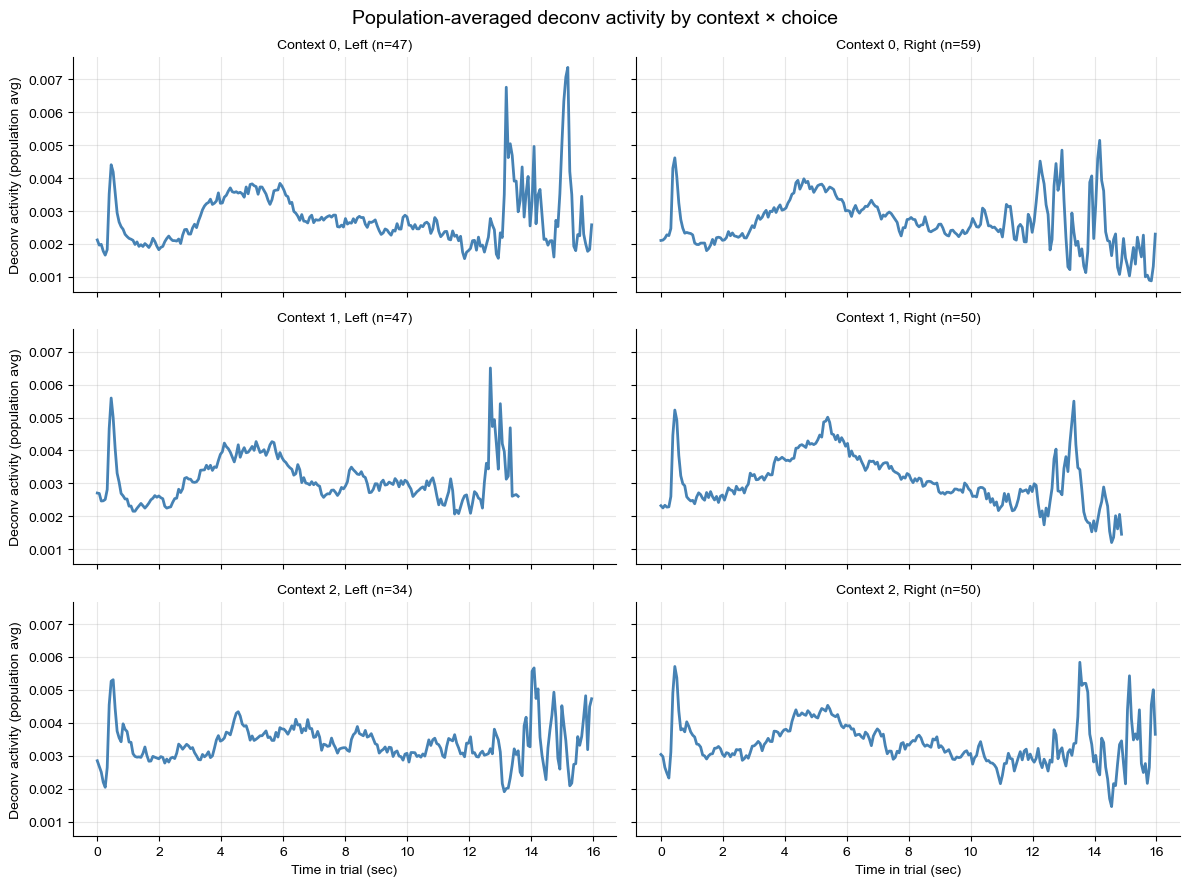

In [11]:
# Cell 10: Plot population-averaged deconv activity
fig, axes = plt.subplots(len(contexts), len(choices),
                         figsize=(12, 3*len(contexts)),
                         sharex=True, sharey=True)
fig.suptitle("Population-averaged deconv activity by context × choice",
             fontsize=14, y=0.98)

for i_ctx, ctx in enumerate(contexts):
    for j_ch, ch in enumerate(choices):
        ax = axes[i_ctx, j_ch]

        mean_trace, n_trials = trial_average_population(ctx, ch)
        if mean_trace is None or n_trials == 0:
            ax.text(0.5, 0.5, "No trials", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
            continue

        label = f"Context {ctx}, {'Left' if ch == 0 else 'Right'} (n={n_trials})"
        ax.plot(time_axis, mean_trace, color='steelblue', lw=2)
        ax.set_title(label, fontsize=10)
        ax.grid(alpha=0.3)

        if j_ch == 0:
            ax.set_ylabel("Deconv activity (population avg)")
        if i_ctx == len(contexts)-1:
            ax.set_xlabel("Time in trial (sec)")

plt.tight_layout()
plt.show()